In [7]:
import pandas as pd

df = pd.read_csv("train.csv")
print(df.shape)
df.head()

(9800, 18)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [8]:
df.info()
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float64
dtypes: float64(2), int6

In [9]:
# 1. Blank postal codes fill pannu (Burlington, Vermont = 5401)
df["Postal Code"] = df["Postal Code"].fillna(5401).astype(int)

# 2. Date columns-ah text-la irundhu real date-ah maathu
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%d/%m/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%d/%m/%Y")

# 3. Check pannu
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9800 non-null   int64         
 1   Order ID       9800 non-null   str           
 2   Order Date     9800 non-null   datetime64[us]
 3   Ship Date      9800 non-null   datetime64[us]
 4   Ship Mode      9800 non-null   str           
 5   Customer ID    9800 non-null   str           
 6   Customer Name  9800 non-null   str           
 7   Segment        9800 non-null   str           
 8   Country        9800 non-null   str           
 9   City           9800 non-null   str           
 10  State          9800 non-null   str           
 11  Postal Code    9800 non-null   int64         
 12  Region         9800 non-null   str           
 13  Product ID     9800 non-null   str           
 14  Category       9800 non-null   str           
 15  Sub-Category   9800 non-null   s

In [10]:
# Date la irundhu Year, Month eduthu pudhu columns add pannu
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month

# Main KPIs
print("Total Revenue:", round(df["Sales"].sum(), 2))
print("Total Orders:", df["Order ID"].nunique())
print("Total Customers:", df["Customer ID"].nunique())

# Year wise sales
print(df.groupby("Year")["Sales"].sum().round(2))

Total Revenue: 2261536.78
Total Orders: 4922
Total Customers: 793
Year
2015    479856.21
2016    459436.01
2017    600192.55
2018    722052.02
Name: Sales, dtype: float64


In [11]:
df.to_csv("cleaned_superstore.csv", index=False)
print("Saved!")

Saved!


In [12]:
# Top 10 products (Sales padi)
print("TOP 10 PRODUCTS")
print(df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10).round(2))

# Region wise sales
print("\nREGION WISE SALES")
print(df.groupby("Region")["Sales"].sum().sort_values(ascending=False).round(2))

# Category wise sales
print("\nCATEGORY WISE SALES")
print(df.groupby("Category")["Sales"].sum().sort_values(ascending=False).round(2))

TOP 10 PRODUCTS
Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.82
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.38
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.48
HON 5400 Series Task Chairs for Big and Tall                                   21870.58
GBC DocuBind TL300 Electric Binding System                                     19823.48
GBC Ibimaster 500 Manual ProClick Binding System                               19024.50
Hewlett Packard LaserJet 3310 Copier                                           18839.69
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.90
GBC DocuBind P400 Electric Binding System                                      17965.07
High Speed Automatic Electric Letter Opener                                    17030.31
Name: Sales, dtype: float64

REGION WISE SALES
Region
West       710219.68
East       66951

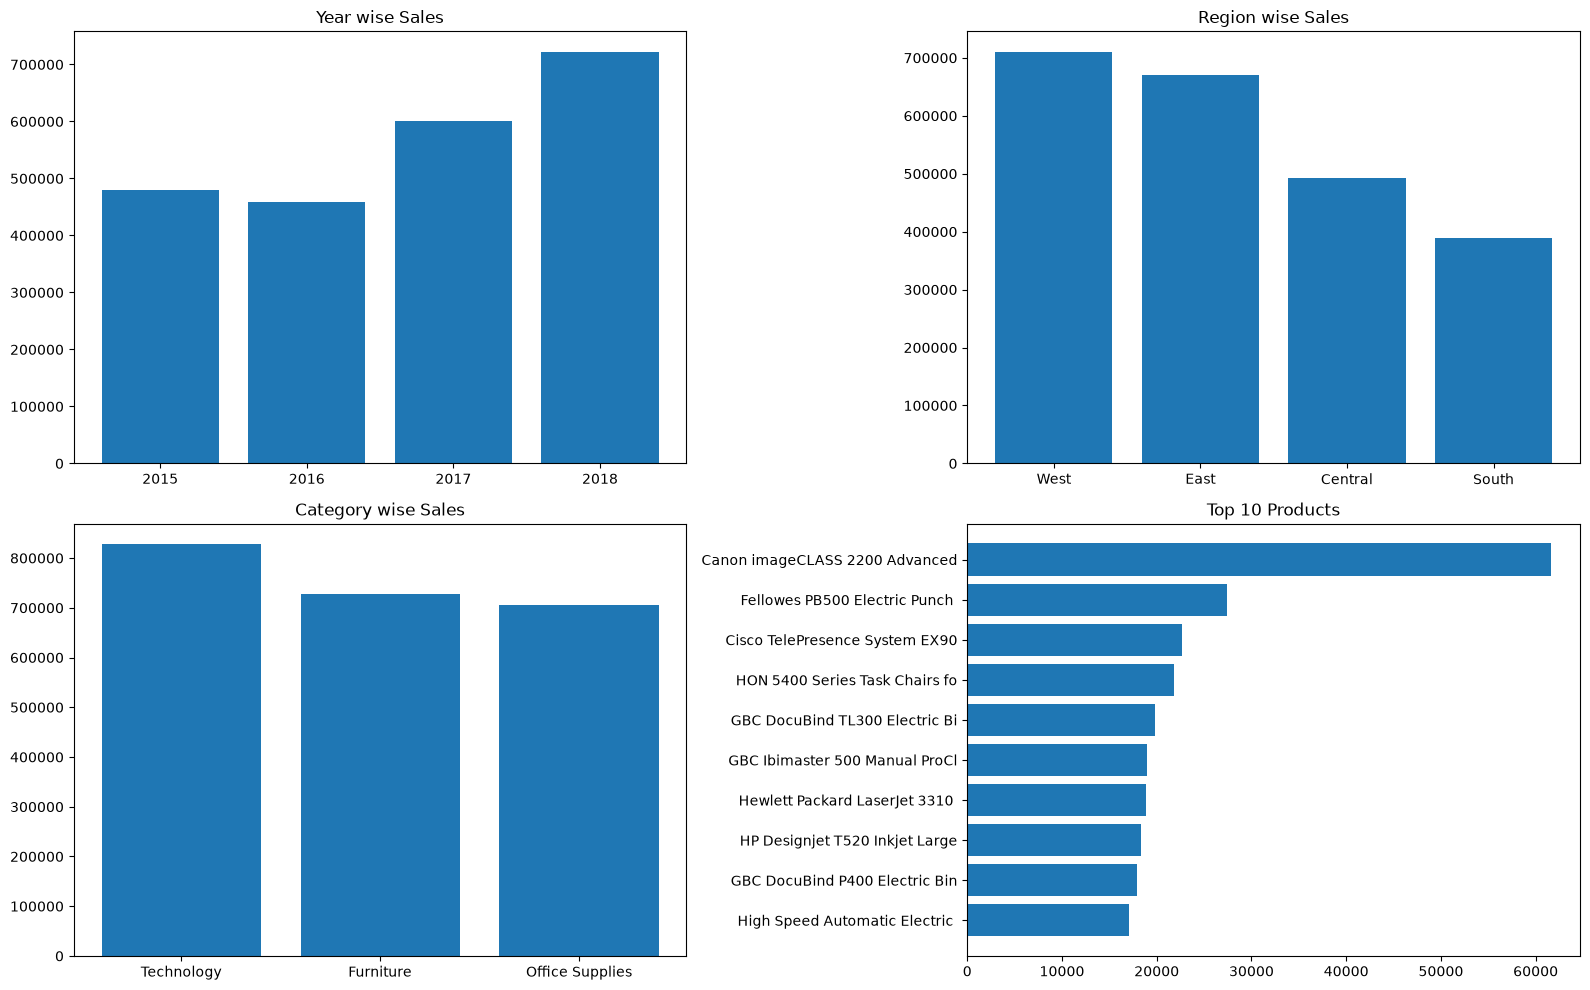

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Chart 1: Year wise sales
yearly = df.groupby("Year")["Sales"].sum()
axes[0, 0].bar(yearly.index.astype(str), yearly.values)
axes[0, 0].set_title("Year wise Sales")

# Chart 2: Region wise sales
region = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
axes[0, 1].bar(region.index, region.values)
axes[0, 1].set_title("Region wise Sales")

# Chart 3: Category wise sales
category = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
axes[1, 0].bar(category.index, category.values)
axes[1, 0].set_title("Category wise Sales")

# Chart 4: Top 10 products
top = df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10)
axes[1, 1].barh(top.index.str[:30], top.values)
axes[1, 1].invert_yaxis()
axes[1, 1].set_title("Top 10 Products")

plt.tight_layout()
plt.savefig("charts.png")
plt.show()